# 📊 Dataset Generation & Exploration (Lost & Found Matcher)
This notebook generates two realistic datasets for our Machine Learning models:
1. `items_dataset.csv`: Labeled descriptions across 7 categories for multiclass **Random Forest Classifier** training.
2. `matching_dataset.csv`: Labeled pairs of lost and found reports with calculated features for binary **Logistic Regression** training.


In [1]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Reproducibility
random.seed(42)
np.random.seed(42)

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
print("Environment initialized successfully.")


Environment initialized successfully.


### Step 1: Base Categories, Campus Locations & Sample Descriptions
We define 7 categories:
- **Wallet, Mobile Phone, Bag, Laptop, Watch, Keys, Other**
along with representative campus locations and realistic descriptions.


In [2]:
CATEGORIES = ["Wallet", "Mobile Phone", "Bag", "Laptop", "Watch", "Keys", "Other"]
LOCATIONS = [
    "Central Library", "Cafeteria", "Computer Lab 3", "Sports Complex",
    "Lecture Hall A", "Admin Block", "Auditorium", "Main Gate",
    "Science Block", "Student Center"
]
COLORS = ["Black", "Brown", "Blue", "Silver", "Grey", "Red", "White", "Green", "Golden"]

SAMPLE_ITEMS = [
    ("Leather Wallet", "Wallet", "Black", "Central Library", "Black leather bi-fold wallet containing student ID card and cash."),
    ("Slim Cardholder", "Wallet", "Brown", "Cafeteria", "Brown slim leather cardholder with credit cards and canteen token."),
    ("Zip Wallet", "Wallet", "Blue", "Student Center", "Navy blue fabric wallet with zipper pocket and metro pass inside."),
    ("iPhone 13", "Mobile Phone", "Blue", "Central Library", "Midnight blue iPhone 13 with clear silicone case and cracked screen protector."),
    ("Samsung Galaxy S22", "Mobile Phone", "Black", "Computer Lab 3", "Phantom black Samsung Galaxy S22 with black ring stand cover."),
    ("OnePlus 11", "Mobile Phone", "Green", "Cafeteria", "Emerald green OnePlus 11 phone with frosted glass back and sandstone case."),
    ("Backpack", "Bag", "Black", "Central Library", "Black Wildcraft water resistant backpack with 15-inch laptop sleeve."),
    ("Gym Duffle Bag", "Bag", "Red", "Sports Complex", "Red Nike duffle bag containing sports shoes, gym towel, and shaker."),
    ("Dell Inspiron 15", "Laptop", "Silver", "Computer Lab 3", "Silver Dell Inspiron 15.6 inch laptop with Intel Core i5 sticker."),
    ("MacBook Air M2", "Laptop", "Grey", "Central Library", "Space grey Apple MacBook Air M2 13-inch with dark keyboard skin."),
    ("Analog Wristwatch", "Watch", "Silver", "Lecture Hall A", "Silver stainless steel chain Casio quartz analog wristwatch."),
    ("Apple Watch Series 8", "Watch", "Black", "Sports Complex", "Midnight aluminum 45mm Apple Watch Series 8 with black sport loop."),
    ("Bike Key Bunch", "Keys", "Silver", "Main Gate", "Pair of Honda Activa scooter keys with red rubber keychain and locker key."),
    ("Hostel Room Keys", "Keys", "Silver", "Central Library", "Two Godrej cylinder door keys with acrylic tag marked Room 304."),
    ("Scientific Calculator", "Other", "Black", "Lecture Hall A", "Casio fx-991EX ClassWiz scientific engineering calculator with sliding cover."),
    ("Stainless Steel Water Bottle", "Other", "Blue", "Central Library", "Insulated blue Milton steel thermos flask with carry handle.")
]
print(f"Sample items defined: {len(SAMPLE_ITEMS)}")


Sample items defined: 16


### Step 2: Generating `items_dataset.csv`
We create multiple realistic natural language descriptions for each item type using varied templates to simulate real campus users.


In [3]:
from generate_dataset import generate_items_dataset
df_items = generate_items_dataset()
print("First 5 rows of items dataset:")
print(df_items.head())
print(f"\nTotal items dataset shape: {df_items.shape}")


Generated 315 item records in D:\ML_Projects\Lost_Found\data\items_dataset.csv
First 5 rows of items dataset:
               item_name  ...                                        description
0  Guitar Capo and Picks  ...  Misplaced guitar capo and picks around Auditor...
1     Samsung Galaxy S22  ...  Report for black samsung galaxy s22 at Compute...
2   Almirah Wardrobe Key  ...  Small brass wardrobe key tied with green ribbo...
3             Camera Bag  ...  Misplaced camera bag around Auditorium. Padded...
4         MacBook Air M2  ...  Found grey macbook air m2. Space grey Apple Ma...

[5 rows x 5 columns]

Total items dataset shape: (315, 5)


### Step 3: Generating `matching_dataset.csv`
We generate positive (is_match = 1) and negative (is_match = 0) item pairs.
For each pair, we calculate:
- `text_similarity` (TF-IDF Cosine Similarity)
- `same_category` (1 or 0)
- `same_color` (1 or 0)
- `same_location` (1 or 0)
- `date_diff_days` (difference in days)


In [4]:
from generate_dataset import generate_matching_dataset
df_matching = generate_matching_dataset()
print("First 5 rows of matching dataset:")
print(df_matching.head())
print(f"\nTotal matching dataset shape: {df_matching.shape}")


Generated 225 matching pairs records in D:\ML_Projects\Lost_Found\data\matching_dataset.csv
Match distribution:
is_match
0    120
1    105
Name: count, dtype: int64
First 5 rows of matching dataset:
                                           lost_desc  ...  is_match
0      Navy blue zip wallet lost near student center  ...         1
1  Missing item: Black Wildcraft school backpack ...  ...         0
2  Missing item: Silver Casio analog metal watch ...  ...         0
3         Dell silver laptop Inspiron 15 lost in lab  ...         0
4  Missing item: Pair of brass padlock keys lost ...  ...         0

[5 rows x 8 columns]

Total matching dataset shape: (225, 8)


### Step 4: Exploratory Data Analysis & Visualizations


Dataset generation complete and verified!


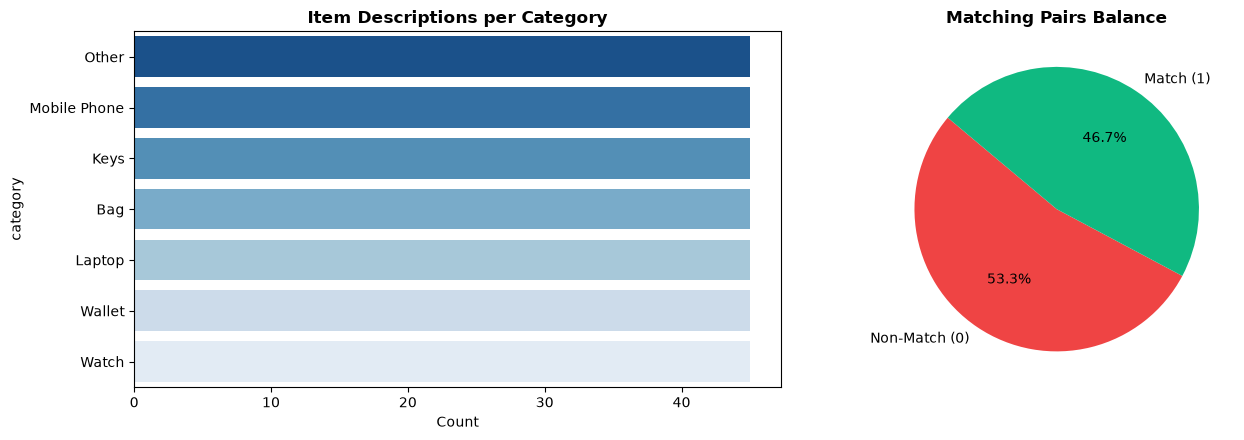

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Category distribution
cat_counts = df_items["category"].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette="Blues_r", ax=axes[0])
axes[0].set_title("Item Descriptions per Category", fontweight='bold')
axes[0].set_xlabel("Count")

# Match vs Non-Match distribution
match_counts = df_matching["is_match"].value_counts()
axes[1].pie(match_counts.values, labels=["Non-Match (0)", "Match (1)"], autopct="%1.1f%%", colors=["#EF4444", "#10B981"], startangle=140)
axes[1].set_title("Matching Pairs Balance", fontweight='bold')

plt.tight_layout()
plt.show()

print("Dataset generation complete and verified!")
